# E4：付録B.1（a9a，MSE・BCE）の再実施

`programs/analysis_e4.py` を呼び出し，集計結果（表と図）を表示する．実験とプログラムの説明は `programs/ex008_e4_a9a/README.md` を参照する．

- `EXISTING`：旧実装の ASA-SVRG（既存のログ）の実験ディレクトリ．空の辞書にすると旧実装を重ねない．
- `LOSSES_TO_SHOW`，`FIGURE_KINDS`：表示する実験と図の種類（`budget31`，`budget31_with_old`，`full`，`full_with_old`）．

In [1]:
import os
import sys

sys.path.insert(0, os.path.join(os.getcwd(), "programs"))
import analysis_e4 as a

# 旧実装の ASA-SVRG（既存のログ）．programs_review の外にあるため，パスはここで指定する．
EXISTING = {
    "mse": os.path.abspath("../outputs/ex000_a9a_least_squares"),
    "bce": os.path.abspath("../outputs/ex0001_a9a_logistic"),
}
EXISTING = {k: v for k, v in EXISTING.items() if os.path.isdir(v)}
LOSSES_TO_SHOW = ["mse", "bce"]
FIGURE_KINDS = ["budget31", "budget31_with_old"]

result = a.write_summary(EXISTING)
print(result["summary_path"])

/home/user/workspace/ASAI_SVRG_programs/programs_review/outputs/e4_summary.md


## 集計表（outputs/e4_summary.md）

In [2]:
from IPython.display import Markdown, display

with open(result["summary_path"]) as f:
    display(Markdown(f.read()))

# E4：付録B.1（a9a，MSE・BCE）の再実施（集計結果）

値は5シードの平均 ± 標準誤差である．「≤31」は $ \#\mathrm{grad}/N \le 31 $ の最後の評価点，「100外側ループ」は100外側ループ終了時（打ち切りの場合は打ち切り直前）の評価点の値である．評価点の $ \#\mathrm{grad}/N $ の列は「≤31 の評価点 / 最終の評価点」を示す．SVRG系の手法は内側ループの開始点を `inner_start="snapshot"`（$ {\mathbf w}_{s}^{0} \leftarrow {\mathbf z}_{s} $）とした．旧実装の ASA-SVRG は既存のログ（`last_iterate`）であり，参考として示す．テスト精度の試行間の標準偏差は，$ 0 < \#\mathrm{grad}/N \le 31 $ の各評価点における5シードの標本標準偏差の平均である．

## a9a, MSE (nonconvex)

| 手法 | シード数 | 評価点の $ \#\mathrm{grad}/N $ | $ \Vert\nabla f({\mathbf z}_{s})\Vert^{2} $（≤31） | $ \Vert\nabla f({\mathbf z}_{s})\Vert^{2} $（100外側ループ） | 近似誤差（≤31） | 近似誤差（100外側ループ） | テスト精度（≤31） | テスト精度（100外側ループ） | テスト精度の試行間の標準偏差（≤31の平均） | 打ち切り数 | $ f({\mathbf z}_{s}) $（≤31） | $ f({\mathbf z}_{s}) $（100外側ループ） |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| SGD | 5 | 31 / 100 | 2.712e-03 ± 1.6e-03 | 2.172e-03 ± 1.2e-03 | （適用外） | （適用外） | 0.8333 ± 0.0079 | 0.8367 ± 0.0056 | 0.0086 | 0 | 0.116277 ± 0.004341 | 0.117447 ± 0.006300 |
| SVRG | 5 | 31 / 301 | 1.744e-07 ± 1.3e-07 | 7.627e-12 ± 7.5e-13 | 0.000e+00 ± 0.0e+00 | 0.000e+00 ± 0.0e+00 | 0.8499 ± 0.0018 | 0.8497 ± 0.0021 | 0.0048 | 0 | 0.103498 ± 0.000097 | 0.103435 ± 0.000097 |
| NFG-SVRG | 5 | 30 / 200 | 3.759e-06 ± 1.5e-06 | 1.102e-07 ± 1.1e-07 | 2.750e-06 ± 1.4e-06 | 2.776e-08 ± 2.8e-08 | 0.8454 ± 0.0035 | 0.8466 ± 0.0015 | 0.0305 | 0 | 0.128531 ± 0.010958 | 0.117488 ± 0.008667 |
| ASA-SVRG | 5 | 30 / 200 | 2.251e-06 ± 2.2e-06 | 7.882e-11 ± 4.5e-11 | 2.979e-05 ± 3.0e-05 | 8.597e-14 ± 6.4e-14 | 0.8459 ± 0.0046 | 0.8470 ± 0.0031 | 0.0158 | 0 | 0.113835 ± 0.010253 | 0.112187 ± 0.008715 |
| ASA-SVRG（旧実装，`last_iterate`，参考） | 5 | 30 / 200 | 8.836e-07 ± 6.1e-07 | 6.544e-11 ± 5.8e-11 | 7.872e-08 ± 5.3e-08 | 2.036e-13 ± 2.0e-13 | 0.7931 ± 0.0206 | 0.8131 ± 0.0220 | 0.0437 | 0 | 0.192846 ± 0.029633 | 0.164994 ± 0.031555 |


シードごとの100外側ループ終了時の $ f({\mathbf z}_{s}) $（括弧内はテスト精度）．参照値 `f_star_reference` は L-BFGS-B で求めた値である：

| 手法 | シード0 | シード1 | シード2 | シード3 | シード4 |
|---|---:|---:|---:|---:|---:|
| SGD | 0.137862（0.8189） | 0.107601（0.8431） | 0.108416（0.8474） | 0.106744（0.8459） | 0.126613（0.8284） |
| SVRG | 0.103302（0.8508） | 0.103268（0.8462） | 0.103585（0.8477） | 0.103278（0.8465） | 0.103744（0.8575） |
| NFG-SVRG | 0.103305（0.8505） | 0.103268（0.8462） | 0.103598（0.8474） | 0.141039（0.8413） | 0.136231（0.8477） |
| ASA-SVRG | 0.147047（0.8379） | 0.103271（0.8456） | 0.103589（0.8477） | 0.103281（0.8462） | 0.103749（0.8575） |
| ASA-SVRG（旧実装，`last_iterate`，参考） | 0.240820（0.7593） | 0.103270（0.8459） | 0.136779（0.8551） | 0.103279（0.8462） | 0.240820（0.7593） |
| 参照値 `f_star_reference` | 0.103299 | 0.103266 | 0.103582 | 0.103275 | 0.103741 |


学習の前半の近似誤差（5シードの幾何平均）：

| 手法 | $ \#\mathrm{grad}/N = 2 $ | $ \#\mathrm{grad}/N = 4 $ | $ \#\mathrm{grad}/N = 8 $ | $ \#\mathrm{grad}/N = 16 $ | $ \#\mathrm{grad}/N = 30 $ |
|---|---:|---:|---:|---:|---:|
| NFG-SVRG | 1.20e-29 | 2.79e-04 | 1.70e-05 | 4.34e-05 | 1.03e-06 |
| ASA-SVRG | 1.37e-29 | 2.69e-04 | 7.15e-05 | 2.49e-07 | 6.04e-10 |
| ASA-SVRG（旧実装，`last_iterate`，参考） | 1.36e-29 | 2.69e-04 | 2.33e-12 | 6.34e-20 | 7.45e-20 |
| 比 NFG-SVRG / ASA-SVRG | 8.8e-01 | 1.0e+00 | 2.4e-01 | 1.7e+02 | 1.7e+03 |


旧実装のログ：`/home/user/workspace/ASAI_SVRG_programs/outputs/ex000_a9a_least_squares`

## a9a, BCE + L2 (strongly convex)

| 手法 | シード数 | 評価点の $ \#\mathrm{grad}/N $ | 目的関数誤差（≤31） | 目的関数誤差（100外側ループ） | 近似誤差（≤31） | 近似誤差（100外側ループ） | テスト精度（≤31） | テスト精度（100外側ループ） | テスト精度の試行間の標準偏差（≤31の平均） | 打ち切り数 | 実測の縮小率 $ \hat{r} $ |
|---|---|---|---|---|---|---|---|---|---|---|---|
| SGD | 5 | 31 / 100 | 4.732e-02 ± 8.4e-03 | 6.011e-02 ± 2.3e-02 | （適用外） | （適用外） | 0.7984 ± 0.0131 | 0.7910 ± 0.0142 | 0.0282 | 0 | （適用外） |
| SVRG | 5 | 31 / 301 | 4.530e-15 ± 2.4e-15 | 3.331e-17 ± 1.4e-17 | 0.000e+00 ± 0.0e+00 | 0.000e+00 ± 0.0e+00 | 0.8053 ± 0.0019 | 0.8053 ± 0.0019 | 0.0061 | 0 | 0.0395 ± 0.0029 |
| NFG-SVRG | 5 | 30 / 200 | 4.616e-11 ± 2.4e-11 | 2.220e-17 ± 2.2e-17 | 3.955e-16 ± 2.5e-16 | 1.240e-31 ± 1.2e-32 | 0.8053 ± 0.0019 | 0.8053 ± 0.0019 | 0.0136 | 0 | 0.1996 ± 0.0050 |
| ASA-SVRG | 5 | 30 / 200 | 6.661e-17 ± 2.1e-17 | 4.441e-17 ± 2.1e-17 | 2.782e-29 ± 5.0e-30 | 2.706e-29 ± 4.9e-30 | 0.8053 ± 0.0019 | 0.8053 ± 0.0019 | 0.0118 | 0 | 0.0053 ± 0.0002 |
| ASA-SVRG（旧実装，`last_iterate`，参考） | 5 | 30 / 200 | -1.110e-17 ± 2.7e-17 | 0.000e+00 ± 1.8e-17 | 2.777e-29 ± 4.9e-30 | 2.675e-29 ± 4.9e-30 | 0.8053 ± 0.0019 | 0.8053 ± 0.0019 | 0.0118 | 0 | 0.0053 ± 0.0001 |


学習の前半の近似誤差（5シードの幾何平均）：

| 手法 | $ \#\mathrm{grad}/N = 2 $ | $ \#\mathrm{grad}/N = 4 $ | $ \#\mathrm{grad}/N = 8 $ | $ \#\mathrm{grad}/N = 16 $ | $ \#\mathrm{grad}/N = 30 $ |
|---|---:|---:|---:|---:|---:|
| NFG-SVRG | 5.67e-29 | 7.75e-03 | 3.23e-04 | 5.49e-07 | 2.12e-16 |
| ASA-SVRG | 5.89e-29 | 6.36e-05 | 1.00e-10 | 1.99e-21 | 2.61e-29 |
| ASA-SVRG（旧実装，`last_iterate`，参考） | 5.91e-29 | 6.36e-05 | 1.01e-10 | 2.51e-21 | 2.61e-29 |
| 比 NFG-SVRG / ASA-SVRG | 9.6e-01 | 1.2e+02 | 3.2e+06 | 2.8e+14 | 8.1e+12 |


旧実装のログ：`/home/user/workspace/ASAI_SVRG_programs/outputs/ex0001_a9a_logistic`


## 図

- `ex008_e4_a9a/figures/e4_mse_A_primary_budget31.png`
- `ex008_e4_a9a/figures/e4_mse_A_primary_budget31_with_old.png`
- `ex008_e4_a9a/figures/e4_mse_A_primary_full.png`
- `ex008_e4_a9a/figures/e4_mse_A_primary_full_with_old.png`
- `ex008_e4_a9a/figures/e4_mse_B_accuracy_budget31.png`
- `ex008_e4_a9a/figures/e4_mse_B_accuracy_budget31_with_old.png`
- `ex008_e4_a9a/figures/e4_mse_B_accuracy_full.png`
- `ex008_e4_a9a/figures/e4_mse_B_accuracy_full_with_old.png`
- `ex008_e4_a9a/figures/e4_mse_C_approx_error_budget31.png`
- `ex008_e4_a9a/figures/e4_mse_C_approx_error_budget31_with_old.png`
- `ex008_e4_a9a/figures/e4_mse_C_approx_error_full.png`
- `ex008_e4_a9a/figures/e4_mse_C_approx_error_full_with_old.png`
- `ex008_e4_a9a/figures/e4_mse_D_objective_value_budget31.png`
- `ex008_e4_a9a/figures/e4_mse_D_objective_value_budget31_with_old.png`
- `ex008_e4_a9a/figures/e4_mse_D_objective_value_full.png`
- `ex008_e4_a9a/figures/e4_mse_D_objective_value_full_with_old.png`
- `ex008_e4_a9a/figures/e4_bce_A_primary_budget31.png`
- `ex008_e4_a9a/figures/e4_bce_A_primary_budget31_with_old.png`
- `ex008_e4_a9a/figures/e4_bce_A_primary_full.png`
- `ex008_e4_a9a/figures/e4_bce_A_primary_full_with_old.png`
- `ex008_e4_a9a/figures/e4_bce_B_accuracy_budget31.png`
- `ex008_e4_a9a/figures/e4_bce_B_accuracy_budget31_with_old.png`
- `ex008_e4_a9a/figures/e4_bce_B_accuracy_full.png`
- `ex008_e4_a9a/figures/e4_bce_B_accuracy_full_with_old.png`
- `ex008_e4_a9a/figures/e4_bce_C_approx_error_budget31.png`
- `ex008_e4_a9a/figures/e4_bce_C_approx_error_budget31_with_old.png`
- `ex008_e4_a9a/figures/e4_bce_C_approx_error_full.png`
- `ex008_e4_a9a/figures/e4_bce_C_approx_error_full_with_old.png`


## 図

(A) MSE は $ \|\nabla f({\mathbf z}_{s})\|^{2} $，BCE は目的関数誤差．(B) テスト精度．(C) 近似誤差（NFG-SVRG・ASA-SVRG）．(D) MSE のみ，$ f({\mathbf z}_{s}) $（補足）．`_with_old` は旧実装の ASA-SVRG（`last_iterate`）を破線で重ねた確認用の図である．

e4_mse_A_primary_budget31.png


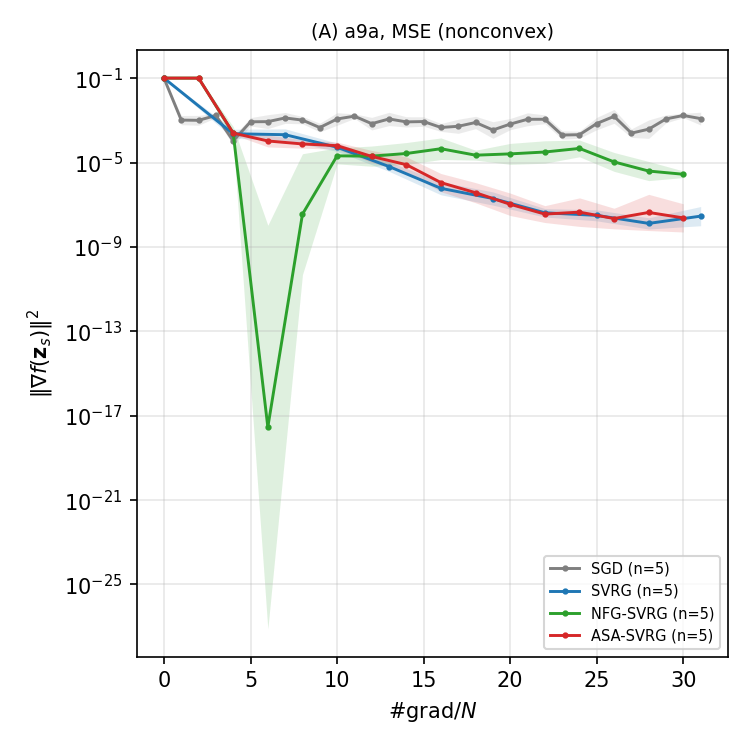

e4_mse_A_primary_budget31_with_old.png


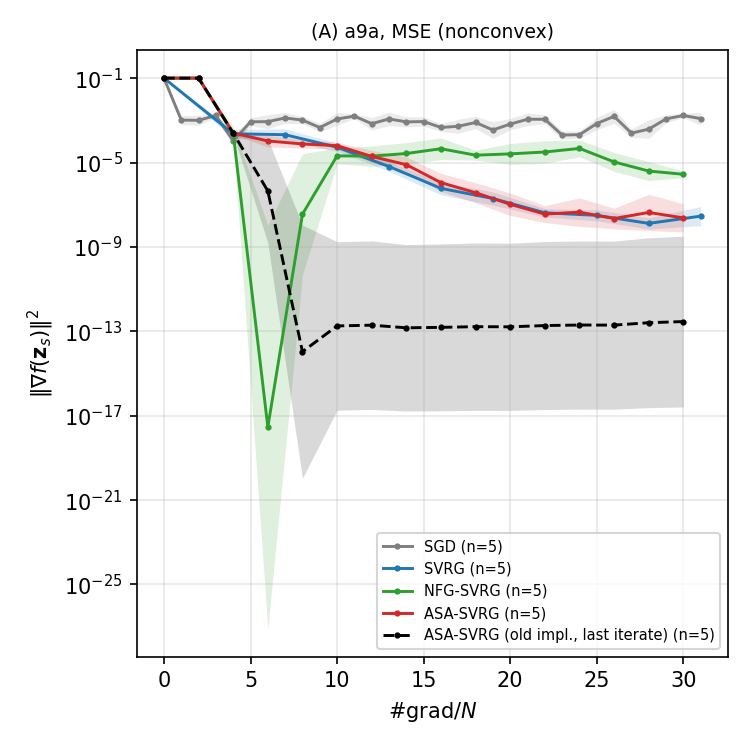

e4_mse_B_accuracy_budget31.png


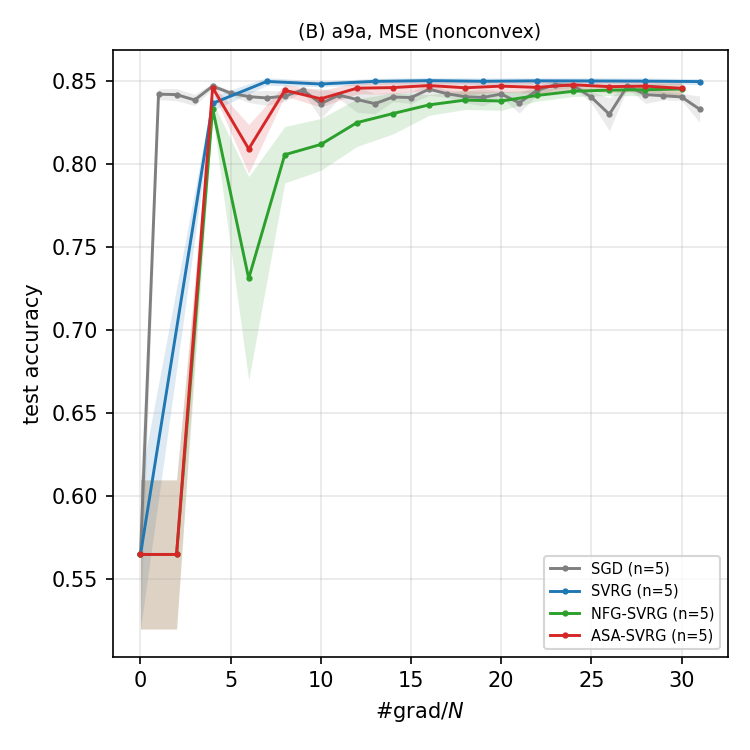

e4_mse_B_accuracy_budget31_with_old.png


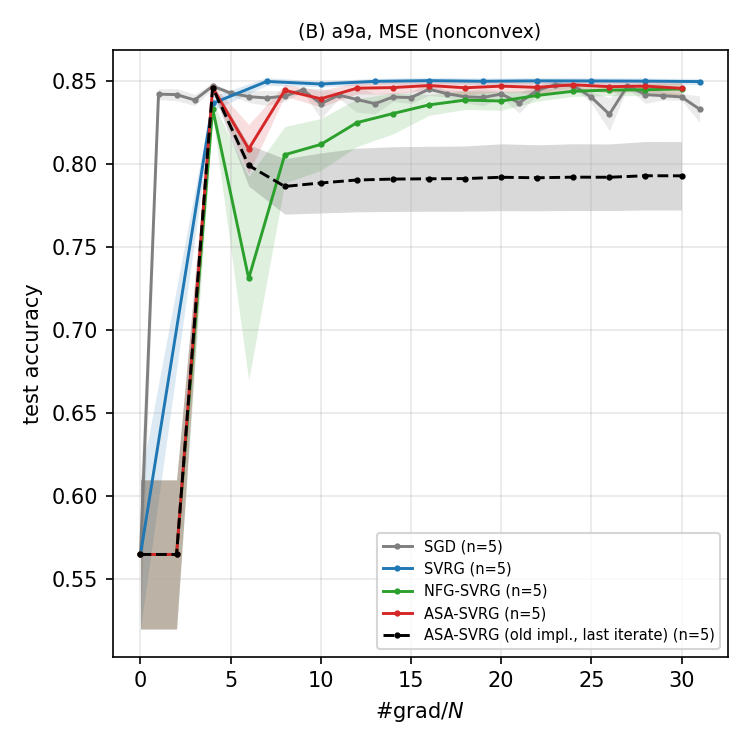

e4_mse_C_approx_error_budget31.png


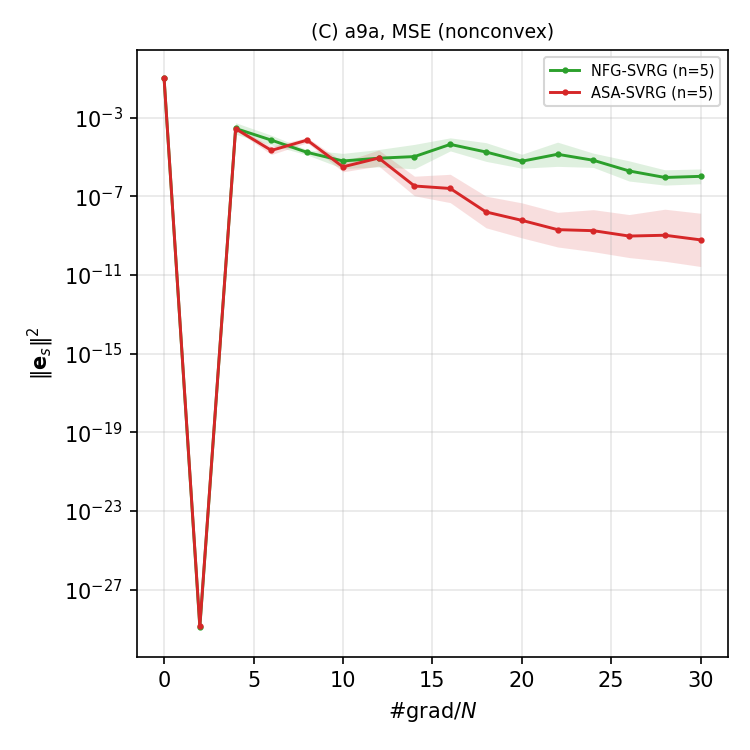

e4_mse_C_approx_error_budget31_with_old.png


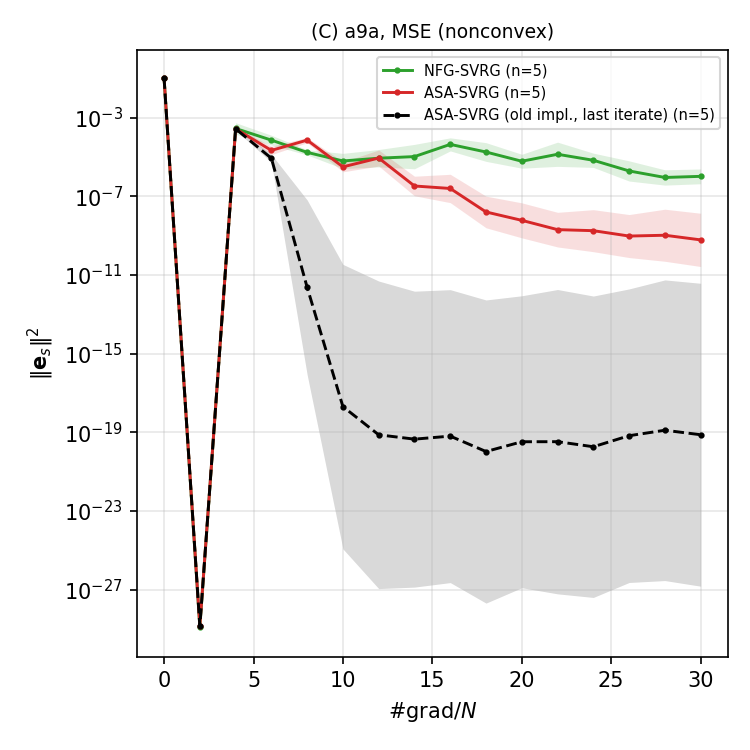

e4_mse_D_objective_value_budget31.png


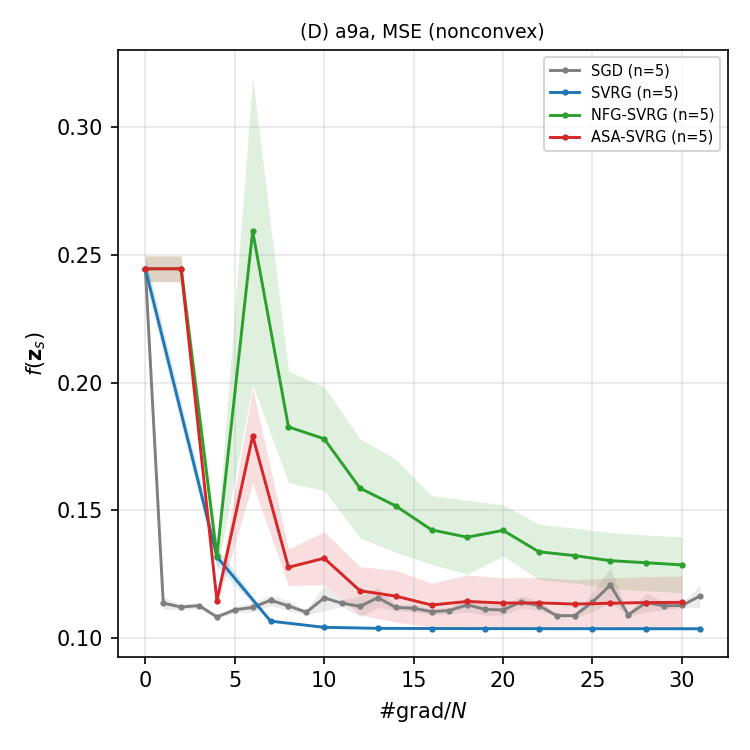

e4_mse_D_objective_value_budget31_with_old.png


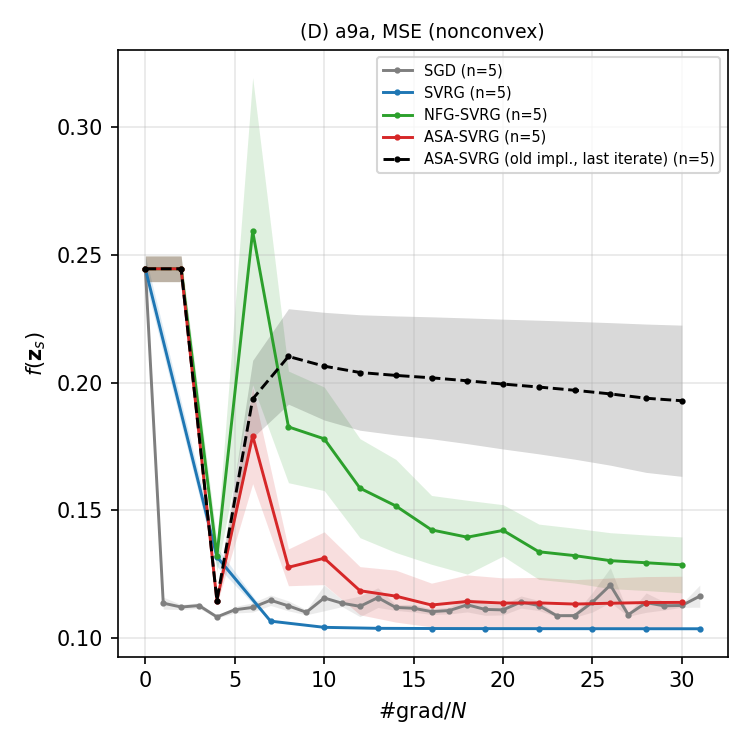

e4_bce_A_primary_budget31.png


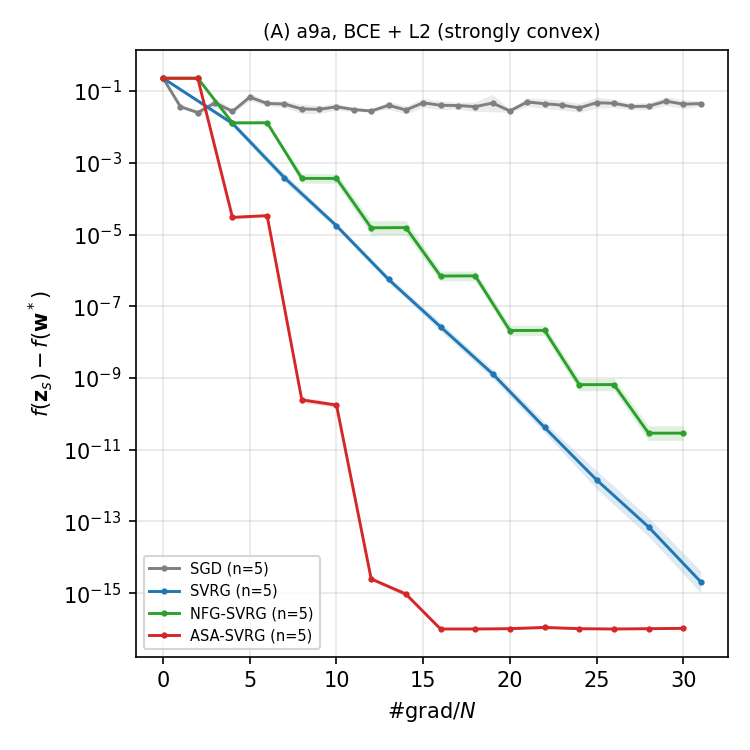

e4_bce_A_primary_budget31_with_old.png


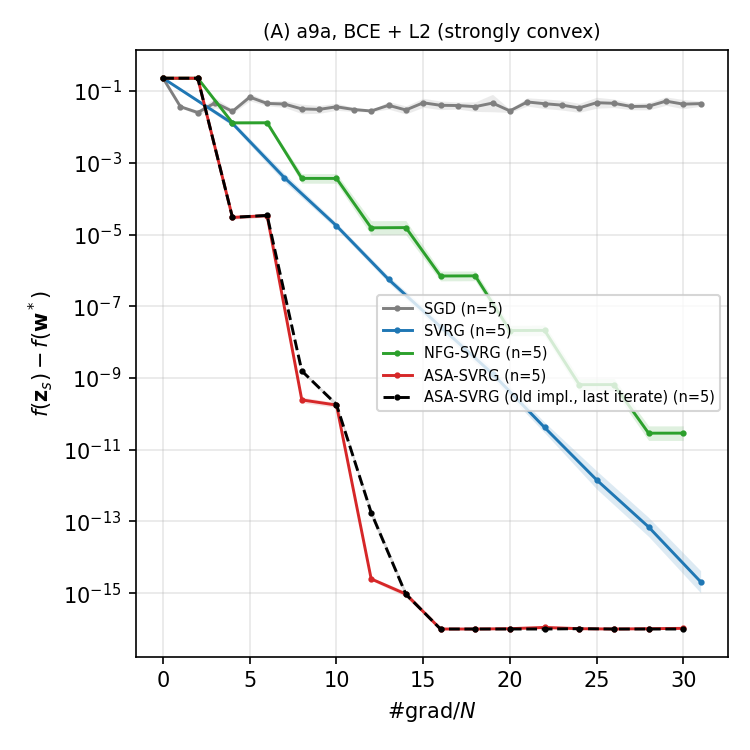

e4_bce_B_accuracy_budget31.png


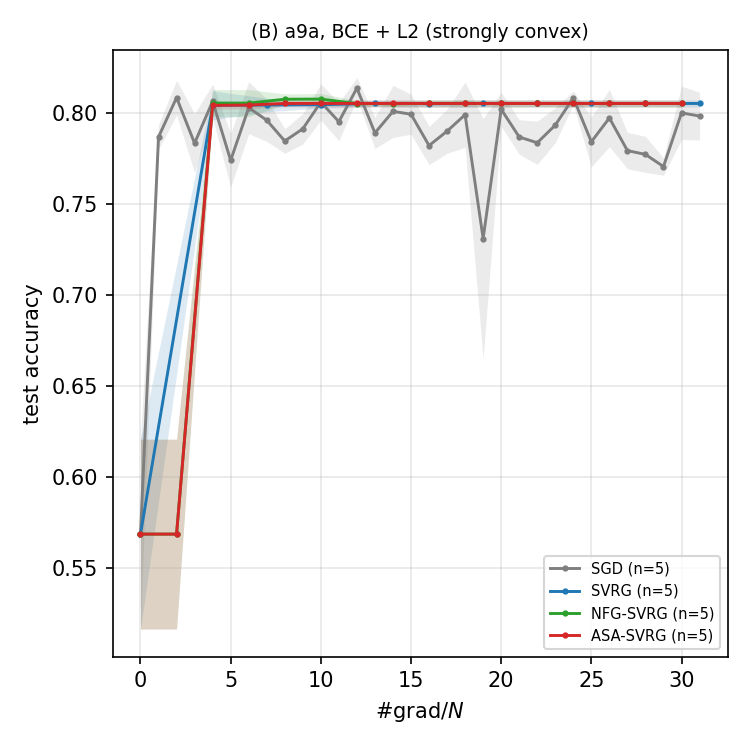

e4_bce_B_accuracy_budget31_with_old.png


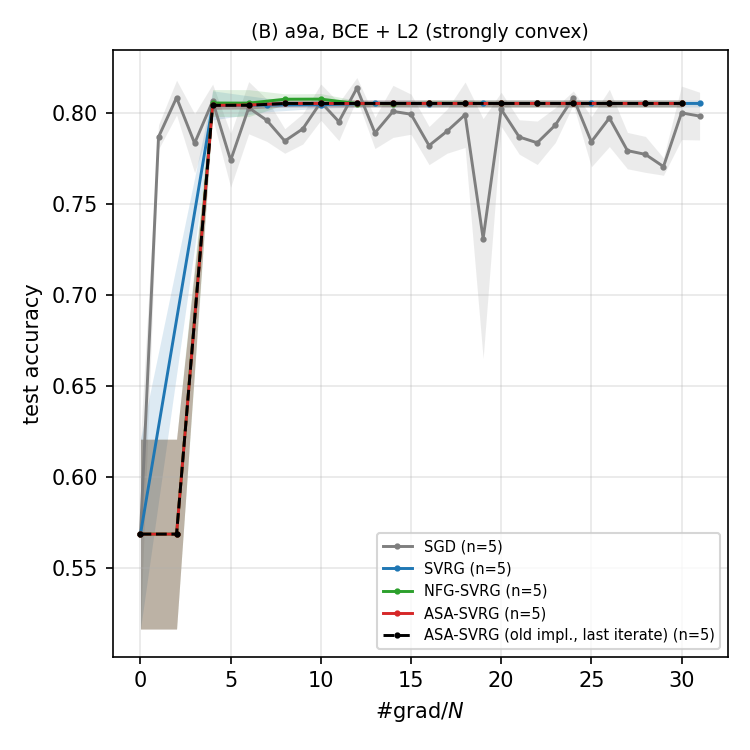

e4_bce_C_approx_error_budget31.png


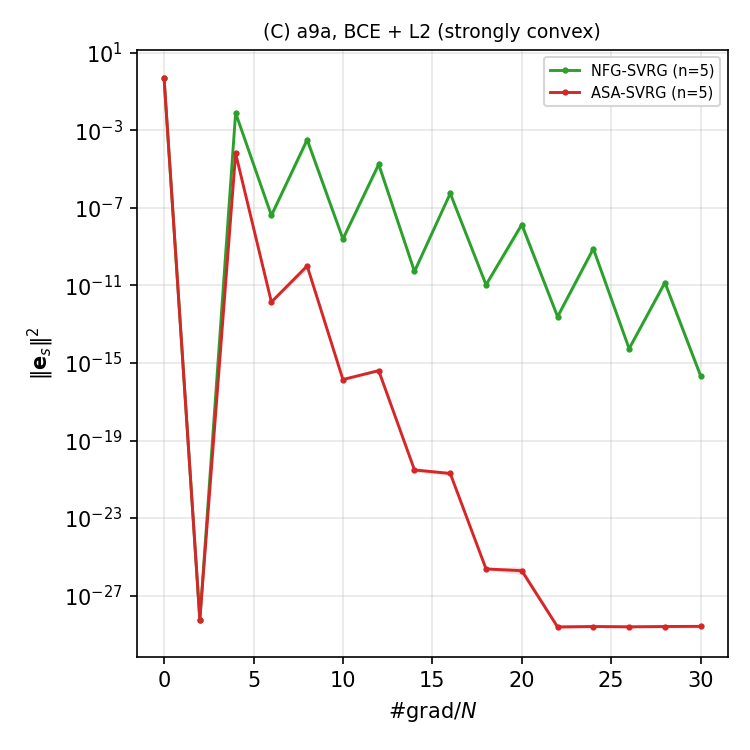

e4_bce_C_approx_error_budget31_with_old.png


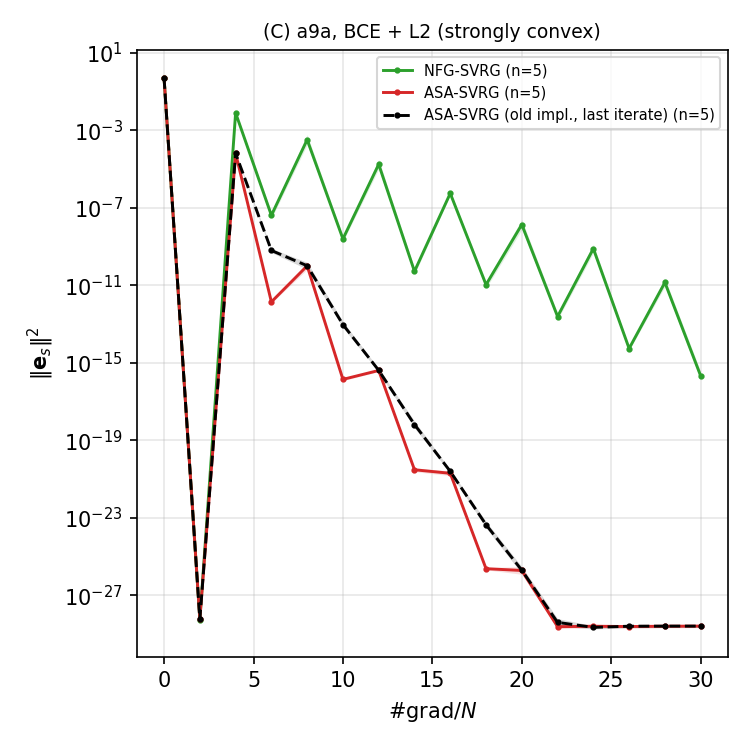

In [3]:
from IPython.display import Image

for loss in LOSSES_TO_SHOW:
    for path in result["figures"][loss]:
        name = os.path.basename(path)[:-4]
        if any(name.endswith(k) for k in FIGURE_KINDS):
            print(os.path.basename(path))
            display(Image(path, width=420))